# Fleurs réelles — SVM + RBF (version simple)

**Objectif :** tester tes deux algorithmes **C++**, afficher une matrice de confusion, tester une image, puis exporter les paramètres appris pour Streamlit.

**Ordre :** exécuter les cellules **1 → 7**. Le notebook original de tests synthétiques reste inchangé.

**Prérequis :** `images_utils.py` à côté de ce notebook, `numpy`, `Pillow`, `matplotlib`, et ta `libPA_V2.dll` compilée (avec OSQP).

## 1 — Configuration : change seulement les chemins et les nombres

In [1]:
from pathlib import Path
import ctypes, time, json
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import images_utils as iu

DATASET_DIR = Path("./dataset")
DLL_PATH = Path("./libPA_V2.dll")
TAILLE = 8                   # images 256x256 sur disque -> 8x8 RGB -> 192 entrées
N_TRAIN_PAR_CLASSE = 30      # 30 d'abord ; essaie 100 plus tard
N_TEST_PAR_CLASSE = 30       # aperçu rapide, puis None pour toutes les images test
SEED = 42
SVM = dict(kernel=0, C=1.0, gamma=0.01, degree=2)  # 0 linéaire ; 1 polynomial ; 2 RBF
RBF = dict(K=10, gamma=0.01, lam=1e-3, maxIterations=100)
OUTPUT_DIR = Path('exports_svm_rbf')
OUTPUT_DIR.mkdir(exist_ok=True)

assert DLL_PATH.is_file(), f"DLL introuvable : {DLL_PATH}"
assert iu.organisation(str(DATASET_DIR)), f"Dataset introuvable : {DATASET_DIR}"
print('DLL :', DLL_PATH)
print('Dataset :', DATASET_DIR)

DLL : libPA_V2.dll
Dataset : dataset


## 2 — Charger les fleurs, nettoyer l’échantillon et séparer train / validation

On prélève **30 images par classe** dans le train et 30 dans le test, pour démarrer vite. La validation (20 % des images train retenues) sert à vérifier les modèles. Les images de test restent **hors entraînement**. Le nettoyage simple retire les copies identiques ou retournées *dans cet échantillon* ; ce n'est pas encore le nettoyage exhaustif du MLP.

In [2]:
CLASSES = iu.lister_classes_dataset(str(DATASET_DIR))
assert len(CLASSES) == 3, f"Trois classes attendues : {CLASSES}"
rng = np.random.default_rng(SEED)

def choisir_par_classe(y, nombre):
    if nombre is None: return np.arange(len(y))
    parts = [rng.choice(np.flatnonzero(y == k), size=min(nombre, int((y == k).sum())), replace=False)
             for k in range(len(CLASSES))]
    return np.sort(np.concatenate(parts))

# Chargement direct dans la résolution choisie : pas besoin de garder les images 256x256 en RAM.
imgs_tr, y_tr, chemins_tr, _ = iu.charger_dataset(str(DATASET_DIR), 'train', CLASSES, TAILLE)
imgs_te, y_te, chemins_te, _ = iu.charger_dataset(str(DATASET_DIR), 'test', CLASSES, TAILLE)
i_tr = choisir_par_classe(y_tr, N_TRAIN_PAR_CLASSE)
i_te = choisir_par_classe(y_te, N_TEST_PAR_CLASSE)

# Enlever doublons et images retournées du petit échantillon pour éviter une fuite évidente.
keep_tr, keep_te = iu.nettoyer_train_test(imgs_tr[i_tr], imgs_te[i_te], miroirs=True)
i_tr, i_te = i_tr[keep_tr], i_te[keep_te]

X_train = np.ascontiguousarray(iu.vers_vecteurs(imgs_tr[i_tr]), dtype=np.float64)
y_train = y_tr[i_tr].astype(int)
X_test = np.ascontiguousarray(iu.vers_vecteurs(imgs_te[i_te]), dtype=np.float64)
y_test = y_te[i_te].astype(int)
CHEMINS_TEST = [chemins_te[i] for i in i_te]
fit_idx, val_idx = iu.separer_validation(y_train, fraction=0.2, graine=SEED)
X_fit, y_fit = X_train[fit_idx], y_train[fit_idx]
X_val, y_val = X_train[val_idx], y_train[val_idx]

print('Classes :', CLASSES)
print('Fit :', X_fit.shape, 'Validation :', X_val.shape, 'Test :', X_test.shape)
print('Train par classe :', np.bincount(y_train, minlength=3))
assert min(np.bincount(y_fit, minlength=3)) > 0
assert min(np.bincount(y_test, minlength=3)) > 0
# Libère les grandes matrices de pixels bruts une fois les vecteurs extraits.
del imgs_tr, imgs_te

Classes : ['jasmin', 'jonquille', 'sunflower']
Fit : (72, 192) Validation : (18, 192) Test : (89, 192)
Train par classe : [30 30 30]


## 3 — Interface Python → DLL C++ (trois modèles binaires par algorithme)

In [3]:
lib = ctypes.CDLL(str(DLL_PATH.resolve()))
P = ctypes.POINTER(ctypes.c_double)
V = ctypes.c_void_p
I = ctypes.c_int32
D = ctypes.c_double

def ptr(a):
    return a.ctypes.data_as(P)

def vecteurs(X):
    X = np.ascontiguousarray(np.asarray(X, dtype=np.float64))
    if X.ndim == 1: X = X[None, :]
    return X

# Signatures SVM
lib.create_svm_model.argtypes = [I, D, I, I]; lib.create_svm_model.restype = V
lib.train_svm_model.argtypes = [V, P, P, I, I, D]; lib.train_svm_model.restype = I
lib.decision_svm.argtypes = [V, P]; lib.decision_svm.restype = D
lib.get_num_support_vectors.argtypes = [V]; lib.get_num_support_vectors.restype = I
lib.get_support_vectors.argtypes = [V, P]
lib.get_alphas_y.argtypes = [V, P]
lib.get_W0.argtypes = [V]; lib.get_W0.restype = D
lib.destroy_svm_model.argtypes = [V]
# Signatures réseau RBF
lib.create_rbf_model.argtypes = [I, I, D]; lib.create_rbf_model.restype = V
lib.train_rbf_model.argtypes = [V, P, P, I, I, D, I]; lib.train_rbf_model.restype = I
lib.decision_rbf.argtypes = [V, P]; lib.decision_rbf.restype = D
lib.get_num_rbf_centers.argtypes = [V]; lib.get_num_rbf_centers.restype = I
lib.get_rbf_centers.argtypes = [V, P]
lib.get_rbf_weights.argtypes = [V, P]
lib.destroy_rbf_model.argtypes = [V]

class Modele3Classes:
    def __init__(self, algorithme, cfg):
        self.algo, self.cfg, self.models = algorithme, cfg, []
        self.dim = None

    def close(self):
        for h in self.models:
            (lib.destroy_svm_model if self.algo == 'SVM' else lib.destroy_rbf_model)(h)
        self.models = []

    def fit(self, X, y):
        self.close()
        X = vecteurs(X); y = np.asarray(y)
        self.dim = X.shape[1]
        if len(np.unique(y)) != 3: raise ValueError('Le train doit contenir les trois classes')
        try:
            for c in range(3):
                cible = np.ascontiguousarray(np.where(y == c, 1., -1.), dtype=np.float64)
                if self.algo == 'SVM':
                    h = lib.create_svm_model(self.dim, self.cfg['gamma'], self.cfg['degree'], self.cfg['kernel'])
                else:
                    if self.cfg['K'] > len(X): raise ValueError('K ne peut pas dépasser la taille du train')
                    h = lib.create_rbf_model(self.dim, self.cfg['K'], self.cfg['gamma'])
                if not h: raise RuntimeError('Création C++ impossible')
                self.models.append(h)
                if self.algo == 'SVM':
                    statut = lib.train_svm_model(h, ptr(X), ptr(cible), len(X), self.dim, self.cfg['C'])
                else:
                    statut = lib.train_rbf_model(h, ptr(X), ptr(cible), len(X), self.dim,
                                                 self.cfg['lam'], self.cfg['maxIterations'])
                if statut != 0:  # 1 : solution SVM approchée, valable avec réserve
                    if self.algo == 'SVM' and statut == 1:
                        print(f'SVM classe {CLASSES[c]} : résolution approchée (statut 1)')
                    else:
                        raise RuntimeError(f'{self.algo} C++ : erreur {statut} sur {CLASSES[c]}')
                if self.algo == 'SVM' and lib.get_num_support_vectors(h) <= 0:
                    raise RuntimeError('Aucun vecteur support obtenu')
        except Exception:
            self.close()
            raise
        return self

    def scores(self, X):
        if len(self.models) != 3: raise RuntimeError('Entraîne le modèle avant de prédire')
        X = vecteurs(X)
        if X.shape[1] != self.dim: raise ValueError('Nombre de pixels/variables incorrect')
        fn = lib.decision_svm if self.algo == 'SVM' else lib.decision_rbf
        out = np.column_stack([np.array([fn(h, ptr(row)) for row in X]) for h in self.models])
        if not np.isfinite(out).all(): raise RuntimeError('Scores C++ non finis')
        return out

    def predict(self, X):
        return np.argmax(self.scores(X), axis=1)

print('SVM / RBF C++ prêts.')

SVM / RBF C++ prêts.


## 4 — Premier test : accuracy sur la validation

Si les deux modèles fonctionnent, on réentraîne ensuite sur tout le train sélectionné. Pour changer les hyperparamètres, modifie seulement `SVM` ou `RBF` dans la cellule 1.

In [4]:
for algo, cfg in [('SVM', SVM), ('RBF', RBF)]:
    modele = Modele3Classes(algo, cfg)
    debut = time.perf_counter()
    try:
        modele.fit(X_fit, y_fit)
        p = modele.predict(X_val)
        print(f'{algo:4} | validation : {(p == y_val).mean():.1%} | temps : {time.perf_counter()-debut:.1f} s')
    finally:
        modele.close()

SVM  | validation : 72.2% | temps : 0.0 s
RBF  | validation : 66.7% | temps : 0.0 s


## 5 — Entraînement final sur les images retenues du train + test

⚠️ **Mode de développement** : si tu changes les paramètres après avoir regardé les résultats du test, ce n'est plus une évaluation finale indépendante. Pour le rapport, choisis d'abord les paramètres sur validation, puis exécute le test une seule fois avec un nettoyage exhaustif.

SVM entraîné en 0.0 s
RBF entraîné en 0.0 s
SVM : accuracy test = 76.4% (68/89)
RBF : accuracy test = 71.9% (64/89)


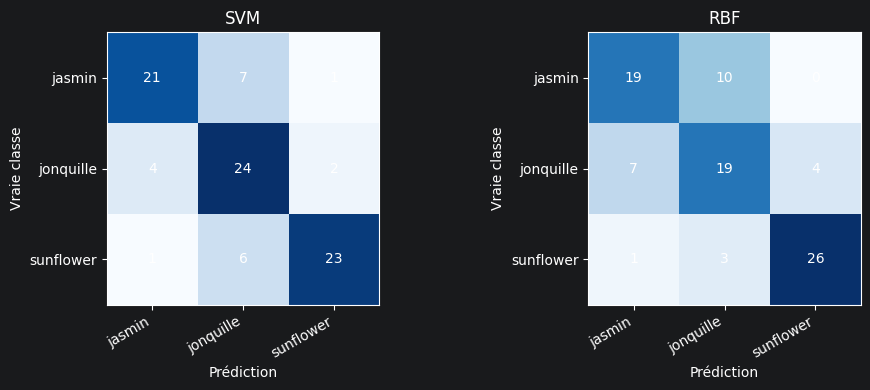

In [5]:
svm_final = Modele3Classes('SVM', SVM)
rbf_final = Modele3Classes('RBF', RBF)

for nom, modele in [('SVM', svm_final), ('RBF', rbf_final)]:
    debut = time.perf_counter()
    modele.fit(X_train, y_train)
    print(f'{nom} entraîné en {time.perf_counter()-debut:.1f} s')

pred_svm = svm_final.predict(X_test)
pred_rbf = rbf_final.predict(X_test)
for nom, p in [('SVM', pred_svm), ('RBF', pred_rbf)]:
    print(f'{nom} : accuracy test = {(p == y_test).mean():.1%} ({(p==y_test).sum()}/{len(y_test)})')

fig, axs = plt.subplots(1, 2, figsize=(10, 4))
for ax, (nom, pred) in zip(axs, [('SVM', pred_svm), ('RBF', pred_rbf)]):
    cm = np.zeros((3,3), dtype=int)
    for vrai, obtenu in zip(y_test, pred): cm[vrai, obtenu] += 1
    im = ax.imshow(cm, cmap='Blues')
    for i in range(3):
        for j in range(3): ax.text(j, i, str(cm[i,j]), ha='center', va='center')
    ax.set_xticks(range(3), CLASSES, rotation=30, ha='right')
    ax.set_yticks(range(3), CLASSES)
    ax.set_xlabel('Prédiction'); ax.set_ylabel('Vraie classe'); ax.set_title(nom)
plt.tight_layout(); plt.show()

## 6 — Tester une image de ton choix (sans réentraîner)

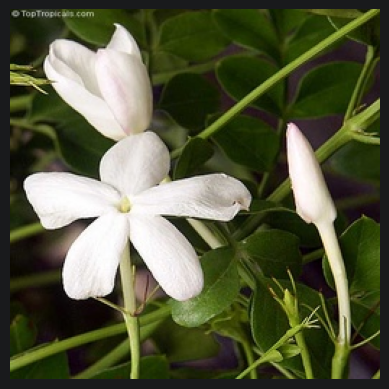

Image : dataset\jasmin\test\jasmin_00136.jpg
SVM -> jasmin | scores = {'jasmin': np.float64(-0.563), 'jonquille': np.float64(-1.161), 'sunflower': np.float64(-1.789)}
RBF -> jonquille | scores = {'jasmin': np.float64(0.008), 'jonquille': np.float64(0.068), 'sunflower': np.float64(-0.949)}


In [6]:
IMAGE_A_TESTER = Path(CHEMINS_TEST[0])  # remplace par un fichier .jpg/.png de ton choix
x = np.ascontiguousarray(iu.preprocess_image(str(IMAGE_A_TESTER), TAILLE), dtype=np.float64)
with Image.open(IMAGE_A_TESTER) as img:
    plt.imshow(img.convert('RGB'))
    plt.axis('off'); plt.show()
print('Image :', IMAGE_A_TESTER)
for nom, modele in [('SVM', svm_final), ('RBF', rbf_final)]:
    sc = modele.scores(x)[0]
    print(f'{nom} -> {CLASSES[int(np.argmax(sc))]} | scores = {dict(zip(CLASSES, np.round(sc, 3)))}')

## 7 — Export `.npz` des modèles entraînés

L'export contient **les paramètres nécessaires à l'inférence** : vecteurs supports, coefficients et biais pour le SVM ; centres et poids pour le RBF. **Il ne faut pas réentraîner dans Streamlit.** Pour intégrer les modèles dans l'application, il faudra ensuite ajouter le code de chargement et de prédiction correspondant (ou des fonctions C++ pour réinjecter ces paramètres).

In [7]:
def exporter(modele, chemin):
    donnees = dict(classes=np.array(CLASSES), taille=np.array(TAILLE),
                   dimensions=np.array(modele.dim), algo=np.array(modele.algo),
                   config=np.array(json.dumps(modele.cfg)))
    for c, h in enumerate(modele.models):
        if modele.algo == 'SVM':
            nsv = int(lib.get_num_support_vectors(h))
            sv = np.empty((nsv, modele.dim), dtype=np.float64)
            ay = np.empty(nsv, dtype=np.float64)
            lib.get_support_vectors(h, ptr(sv))
            lib.get_alphas_y(h, ptr(ay))
            donnees[f'sv_{c}'] = sv
            donnees[f'alphasY_{c}'] = ay
            donnees[f'bias_{c}'] = np.array(lib.get_W0(h))
        else:
            k = int(lib.get_num_rbf_centers(h))
            centers = np.empty((k, modele.dim), dtype=np.float64)
            weights = np.empty(k, dtype=np.float64)
            lib.get_rbf_centers(h, ptr(centers))
            lib.get_rbf_weights(h, ptr(weights))
            donnees[f'centers_{c}'] = centers
            donnees[f'weights_{c}'] = weights
    np.savez_compressed(chemin, **donnees)
    print('Exporté :', chemin)

exporter(svm_final, OUTPUT_DIR / 'svm_fleurs.npz')
exporter(rbf_final, OUTPUT_DIR / 'rbf_fleurs.npz')
# Les modèles restent ouverts pour continuer à tester de nouvelles images.
# Quand tu as fini (et uniquement à ce moment) :
# svm_final.close(); rbf_final.close()

Exporté : exports_svm_rbf\svm_fleurs.npz
Exporté : exports_svm_rbf\rbf_fleurs.npz
